# Huấn luyện VAE bằng GPU Colab trong VS Code

Chọn kernel Colab GPU, chạy phần thiết lập và cell cấu hình chung, rồi chọn cell 6 (sanity check) hoặc cell 7 (train chính). Notebook gọi `models/vae/train.py`, hiển thị log từng epoch và lưu ZIP trên My Drive để bạn tải thủ công.

Để train trên máy, chạy `python models/vae/train.py` từ thư mục gốc project.

## 1. Xác nhận runtime GPU

In [32]:
import subprocess
import sys
import torch

if not torch.cuda.is_available():
    raise RuntimeError(
        'Runtime chưa có GPU. Hãy ngắt kết nối, chọn Colab GPU runtime rồi kết nối lại.'
    )

subprocess.run(['nvidia-smi'], check=True)
gpu = torch.cuda.get_device_properties(0)
print(f'PyTorch: {torch.__version__}')
print(f'GPU: {gpu.name} | VRAM: {gpu.total_memory / 1024**3:.1f} GB')

PyTorch: 2.14.1+cu130
GPU: Tesla T4 | VRAM: 14.6 GB


## 2. Mount Drive và cấu hình dữ liệu

Checkpoint được lưu trên Google Drive. Dataset mặc định nằm trên SSD của VM. Đặt `PERSIST_DATA_ON_DRIVE = True` nếu muốn giữ dataset qua các lần khởi động runtime.

Nếu extension chưa mount được Drive từ cell, chạy **Colab: Mount Google Drive to Server…** trong Command Palette rồi chạy lại cell này.

In [33]:
import os
from pathlib import Path

PERSIST_DATA_ON_DRIVE = False
REPO_URL = 'https://github.com/lucaspham102/DL_ImgGenModel.git'
PROJECT_DIR = Path('/content/DL_ImgGenModel')

from google.colab import drive

my_drive = Path("/content/drive/MyDrive")
if not my_drive.is_dir():
    drive.mount("/content/drive")
if not my_drive.is_dir():
    raise FileNotFoundError(f"Không truy cập được My Drive tại {my_drive}")
STORAGE_ROOT = my_drive / "DL_ImgGenModel_storage"

CKPT_DIR = STORAGE_ROOT / 'checkpoints'
if PERSIST_DATA_ON_DRIVE:
    DATA_ROOT = STORAGE_ROOT / 'data'
    KAGGLE_CACHE = STORAGE_ROOT / 'kagglehub_cache'
else:
    DATA_ROOT = Path('/content/DL_ImgGenModel_runtime/data')
    KAGGLE_CACHE = Path('/content/kagglehub_cache')
for path in (DATA_ROOT, CKPT_DIR, KAGGLE_CACHE):
    path.mkdir(parents=True, exist_ok=True)

# Cache đi theo lựa chọn PERSIST_DATA_ON_DRIVE.
os.environ['KAGGLEHUB_CACHE'] = str(KAGGLE_CACHE)
print('Data:', DATA_ROOT)
print('Checkpoints:', CKPT_DIR)
print('Kaggle cache:', KAGGLE_CACHE)

Data: /content/DL_ImgGenModel_runtime/data
Checkpoints: /content/drive/MyDrive/DL_ImgGenModel_storage/checkpoints
Kaggle cache: /content/kagglehub_cache


## 3. Đồng bộ mã nguồn từ GitHub

In [34]:
import os
import subprocess
import sys

REPO_BRANCH = 'khanh'
if (PROJECT_DIR / '.git').is_dir():
    subprocess.run(['git', 'fetch', REPO_URL, REPO_BRANCH], cwd=PROJECT_DIR, check=True)
    subprocess.run(['git', 'switch', '--detach', 'FETCH_HEAD'], cwd=PROJECT_DIR, check=True)
elif PROJECT_DIR.exists() and any(PROJECT_DIR.iterdir()):
    raise RuntimeError(f'{PROJECT_DIR} đã tồn tại nhưng không phải Git repository.')
else:
    subprocess.run(
        ['git', 'clone', '--branch', REPO_BRANCH, REPO_URL, str(PROJECT_DIR)],
        check=True,
    )

train_script = PROJECT_DIR / 'models/vae/train.py'
if not train_script.is_file():
    raise FileNotFoundError(f'Nhánh {REPO_BRANCH} thiếu file {train_script}.')

os.chdir(PROJECT_DIR)
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))
print(f'Commit đang chạy từ nhánh {REPO_BRANCH}:', flush=True)
subprocess.run(['git', '-C', str(PROJECT_DIR), 'log', '-1', '--oneline'], check=True)

Commit đang chạy từ nhánh khanh:


CompletedProcess(args=['git', '-C', '/content/DL_ImgGenModel', 'log', '-1', '--oneline'], returncode=0)

## 4. Kiểm tra thư viện và CUDA

In [35]:
from importlib.util import find_spec

import numpy
from PIL import Image
import torch
import torchvision

if not torch.cuda.is_available():
    raise RuntimeError("PyTorch chưa nhận GPU. Chọn runtime GPU rồi chạy lại cell.")

print(f"CUDA sẵn sàng: {torch.cuda.get_device_name(0)}")
print(f"PyTorch {torch.__version__}, torchvision {torchvision.__version__}")

def install_if_missing(package):
    if find_spec(package) is None:
        result = subprocess.run(
            [sys.executable, "-m", "pip", "install", package],
            stdout=subprocess.PIPE,
            stderr=subprocess.STDOUT,
            text=True,
        )
        print(result.stdout)
        if result.returncode != 0:
            raise RuntimeError(f"pip không cài được {package}. Xem thông báo pip ở trên.")

CUDA sẵn sàng: Tesla T4
PyTorch 2.14.1+cu130, torchvision 0.29.1+cu130


## 5. Cấu hình W&B

Mặc định `BACKEND = 'none'`. Để ghi log lên W&B, đổi thành `'wandb'` và dùng secret `WANDB_API_KEY` hoặc đăng nhập khi được hỏi.

In [36]:
BACKEND = 'none'
WANDB_PROJECT = 'DL_ImageGenModel'
WANDB_ENTITY = '24022367-vietnam-national-university-hanoi'

if BACKEND == 'wandb':
    install_if_missing('wandb')
    import wandb
    api_key = None
    try:
        from google.colab import userdata
        api_key = userdata.get('WANDB_API_KEY')
    except Exception:
        pass
    wandb.login(key=api_key) if api_key else wandb.login()
    print('W&B đã đăng nhập.')

## 6. Sanity check VAE và trực quan hóa metric

Chạy cell cấu hình chung trước. Cell 6 train với 2.000 ảnh Fashion-MNIST trong 5 epoch. Cell 6 và 7 hiển thị bảng train/validation, ba biểu đồ loss và hai lưới ảnh từ checkpoint tốt nhất. Cuối cell có đường dẫn ZIP trong My Drive.

In [37]:
import os
import re
import subprocess
import sys
from pathlib import Path
from zipfile import ZIP_DEFLATED, ZipFile

BATCH_SIZE = 64
LEARNING_RATE = 5e-4
LATENT_DIM = 128
KL_WEIGHT = 1.0
KL_WARMUP_EPOCHS = 10
SEED = 42
RESUME = True


def vae_paths():
    if not {"PROJECT_DIR", "DATA_ROOT", "CKPT_DIR"} <= globals().keys():
        raise RuntimeError("Chạy phần thiết lập Colab, Drive và mã nguồn trước.")
    return PROJECT_DIR, DATA_ROOT, CKPT_DIR


def save_vae_previews(project, data, dataset, best_path, run_dir, prefix):
    import torch
    from IPython.display import Image, display
    from torchvision.utils import save_image

    if str(project) not in sys.path:
        sys.path.insert(0, str(project))
    from data.dataloader import denormalize, get_dataloaders
    from models.vae.vae import VAE

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    # Checkpoint của script train có kèm trạng thái RNG.
    checkpoint = torch.load(best_path, map_location="cpu", weights_only=False)
    weights = checkpoint["models"]["vae"]
    model = VAE(in_channels=3, latent_dim=weights["encoder.fc_mu.weight"].shape[0]).to(device)
    model.load_state_dict(weights)
    model.eval()

    _, val_loader, _ = get_dataloaders(
        name=dataset, root=str(data), batch_size=8, num_workers=0,
        seed=SEED, validate_integrity=False,
    )
    with torch.inference_mode():
        real, _ = next(iter(val_loader))
        real = real.to(device)
        recon = model.reconstruct(real)
        comparison = denormalize(torch.cat((real, recon)).cpu(), clamp=True)
        generated = denormalize(model.sample(64).cpu(), clamp=True)

    recon_path = run_dir / f"{prefix}_reconstruction.png"
    generated_path = run_dir / f"{prefix}_generated.png"
    save_image(comparison, recon_path, nrow=len(real))
    save_image(generated, generated_path, nrow=8)
    print(f"Ảnh thật (trên) và ảnh tái tạo (dưới), checkpoint epoch {checkpoint['epoch']}")
    display(Image(filename=str(recon_path)))
    print("Ảnh sinh từ nhiễu chuẩn")
    display(Image(filename=str(generated_path)))
    return recon_path, generated_path


def run_vae(run, dataset, epochs, *, subset=None):
    project, data, checkpoint_root = vae_paths()
    if not (project / "models" / "vae" / "train.py").is_file():
        raise FileNotFoundError(f"Không tìm thấy models/vae/train.py tại {project}")

    if dataset == "celeba":
        install_if_missing("kagglehub")

    import matplotlib.pyplot as plt
    import numpy as np
    import pandas as pd
    from IPython.display import display

    run_dir = checkpoint_root / "sanity_local" if run == "sanity" else checkpoint_root
    run_dir.mkdir(parents=True, exist_ok=True)
    prefix = f"sanity_{dataset}" if run == "sanity" else f"vae_{dataset}_training"
    csv_path = run_dir / f"{prefix}_metrics.csv"
    png_path = run_dir / f"{prefix}_curves.png"
    log_path = run_dir / f"{prefix}.log"
    last_path = run_dir / f"vae_{dataset}_last.pt"
    best_path = run_dir / f"vae_{dataset}_best.pt"

    command = [
        sys.executable, "-u", "models/vae/train.py",
        "--dataset", dataset,
        "--data-root", str(data),
        "--ckpt-dir", str(run_dir),
        "--epochs", str(epochs),
        "--batch-size", str(BATCH_SIZE),
        "--lr", str(LEARNING_RATE),
        "--latent-dim", str(LATENT_DIM),
        "--kl-weight", str(KL_WEIGHT),
        "--kl-warmup-epochs", str(min(KL_WARMUP_EPOCHS, epochs)),
        "--seed", str(SEED),
        "--backend", globals().get("BACKEND", "none"),
        "--project", globals().get("WANDB_PROJECT", "DL_ImageGenModel"),
        "--entity", globals().get("WANDB_ENTITY", ""),
    ]
    if subset is not None:
        command.extend(["--subset", str(subset)])
    resumed = RESUME and last_path.is_file()
    if resumed:
        command.extend(["--resume", str(last_path)])
        print(f"Resume từ {last_path}", flush=True)

    epoch_pattern = re.compile(
        r"\[Epoch\s+(\d+)/\d+\s+-\s+[0-9.]+s\]\s+"
        r"Train Loss:\s+(\S+)\s+\(Recon:\s+(\S+),\s+KL:\s+(\S+)\)\s+\|\s+"
        r"Val Loss:\s+(\S+)\s+\(Recon:\s+(\S+),\s+KL:\s+(\S+)\)"
    )
    batch_pattern = re.compile(r"^Epoch \[\d+/\d+\] \| Batch")
    columns = ["Epoch", "Train Loss", "Train Recon", "Train KL", "Val Loss", "Val Recon", "Val KL"]
    rows = []
    with log_path.open("a" if resumed else "w", encoding="utf-8") as log, subprocess.Popen(
        command, cwd=project, env={**os.environ, "PYTHONIOENCODING": "utf-8"},
        stdout=subprocess.PIPE, stderr=subprocess.STDOUT, encoding="utf-8", errors="replace",
    ) as process:
        for line in process.stdout:
            log.write(line)
            log.flush()
            match = epoch_pattern.search(line)
            if match:
                epoch, *values = match.groups()
                rows.append([int(epoch), *map(float, values)])
            if not batch_pattern.match(line):
                print(line, end="", flush=True)
        return_code = process.wait()
    if return_code:
        raise subprocess.CalledProcessError(return_code, command)

    history = pd.DataFrame(rows, columns=columns)
    if resumed and csv_path.is_file():
        previous = pd.read_csv(csv_path)
        if not history.empty:
            previous = previous[previous["Epoch"] < history["Epoch"].min()]
        history = pd.concat([previous, history], ignore_index=True)
    if not resumed and history["Epoch"].tolist() != list(range(1, epochs + 1)):
        raise RuntimeError(f"Cần đủ metric từ epoch 1 đến {epochs}. Kiểm tra log huấn luyện.")
    if history.empty or history["Epoch"].max() < epochs:
        raise RuntimeError(f"Chưa có metric đến epoch {epochs}. Kiểm tra log hoặc tăng EPOCHS khi resume.")
    if not np.isfinite(history[columns[1:]].to_numpy(dtype=float)).all():
        raise RuntimeError("Metric chứa NaN hoặc Inf.")
    history = history.sort_values("Epoch")
    display(history.style.format({column: "{:.2f}" for column in columns[1:]}))
    history.to_csv(csv_path, index=False)

    figure, axes = plt.subplots(1, 3, figsize=(18, 5))
    for axis, title, metric in zip(axes, ["Total Loss", "Reconstruction", "KL Divergence"], ["Loss", "Recon", "KL"]):
        for split in ("Train", "Val"):
            axis.plot(history["Epoch"], history[f"{split} {metric}"], marker="o", label=split)
        axis.set(title=title, xlabel="Epoch", ylabel="Loss")
        axis.grid(alpha=0.3)
        axis.legend()
    figure.suptitle(f"VAE {dataset} · {run}")
    figure.tight_layout()
    figure.savefig(png_path, dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(figure)
    preview_paths = save_vae_previews(project, data, dataset, best_path, run_dir, prefix)
    print(f"Đã lưu checkpoint, log, CSV, biểu đồ và ảnh mẫu tại {run_dir}")

    archive_path = run_dir / f"vae_{run}_{dataset}.zip"
    temp_archive = archive_path.with_suffix(".zip.tmp")
    with ZipFile(temp_archive, "w", compression=ZIP_DEFLATED, compresslevel=1) as archive:
        for path in (best_path, last_path, csv_path, png_path, log_path, *preview_paths):
            archive.write(path, arcname=path.name)
    temp_archive.replace(archive_path)
    print("Tải ZIP trong Google Drive:", archive_path, flush=True)

Resume từ /content/drive/MyDrive/DL_ImgGenModel_storage/checkpoints/sanity_local/vae_fashion_mnist_last.pt
[*] Thiết bị huấn luyện VAE: cuda (Tesla T4)
[*] Đang nạp dữ liệu 'fashion_mnist' từ '/content/DL_ImgGenModel_runtime/data'...
[*] Subset mode: Lấy ngẫu nhiên 2,000 mẫu từ tập train (Seed=42).
[+] Dữ liệu sẵn sàng: 31 batches train | 94 batches val
[*] Đang tải checkpoint từ: /content/drive/MyDrive/DL_ImgGenModel_storage/checkpoints/sanity_local/vae_fashion_mnist_last.pt
[+] Khôi phục thành công! Bắt đầu từ epoch 6, step 155 (Best val loss: 809.40)

============================== BẮT ĐẦU HUẤN LUYỆN VAE (5 EPOCHS) ==============================

[+] Quá trình hoàn tất.


/tmp/ipykernel_948/1643090166.py:138: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  history = pd.concat([previous, history], ignore_index=True)


,Epoch,Train Loss,Train Recon,Train KL,Val Loss,Val Recon,Val KL
0,1,4246.92,4183.74,315.91,2564.67,2234.27,330.40
1,2,1473.24,1385.44,219.49,1175.90,966.49,209.41
2,3,964.77,854.73,183.41,976.75,801.57,175.18
3,4,828.14,698.45,162.11,809.40,634.67,174.73
4,5,747.15,600.93,146.22,713.63,568.43,145.20


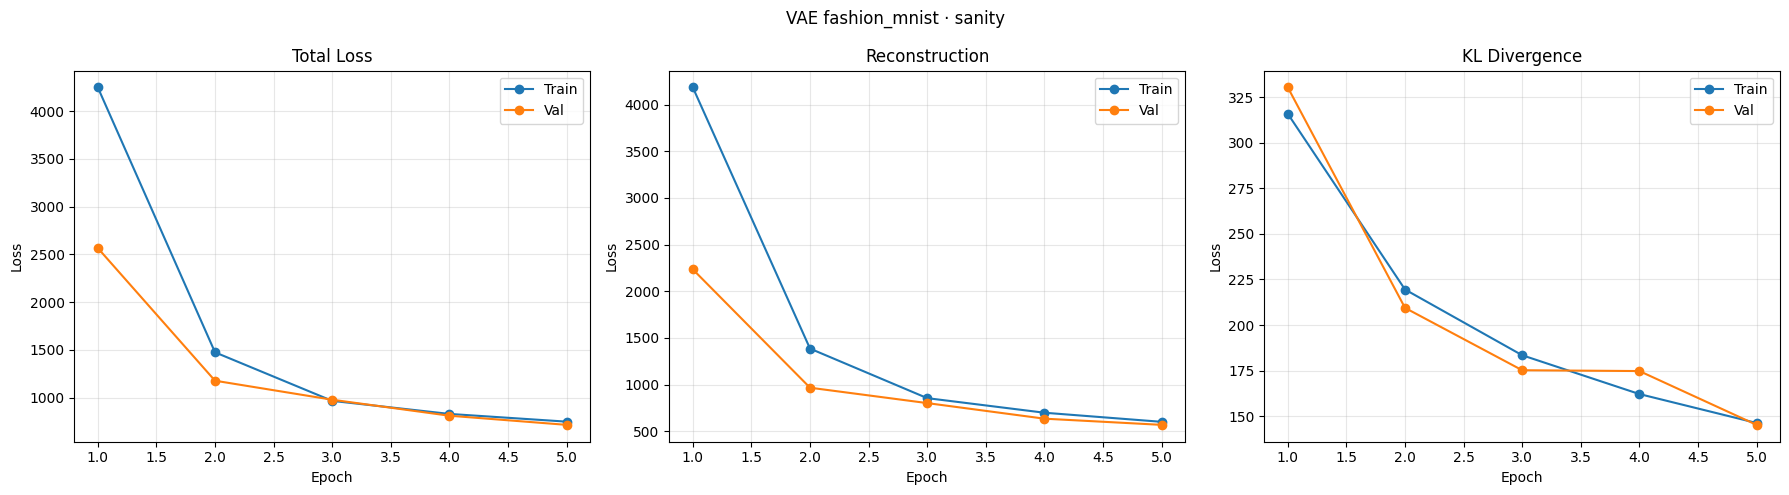

Ảnh thật (trên) và ảnh tái tạo (dưới), checkpoint epoch 5


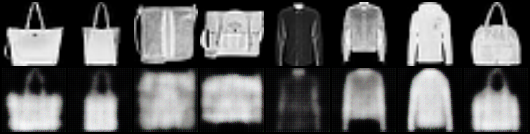

Ảnh sinh từ nhiễu chuẩn


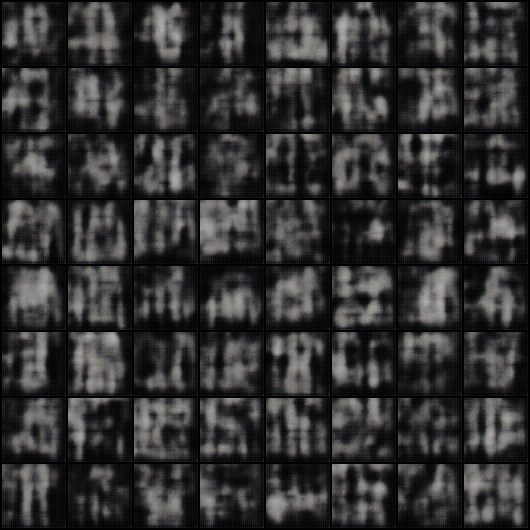

Đã lưu checkpoint, log, CSV, biểu đồ và ảnh mẫu tại /content/drive/MyDrive/DL_ImgGenModel_storage/checkpoints/sanity_local
Tải ZIP trong Google Drive: /content/drive/MyDrive/DL_ImgGenModel_storage/checkpoints/sanity_local/vae_sanity_fashion_mnist.zip


In [38]:
run_vae("sanity", "fashion_mnist", epochs=5, subset=2000)

## 7. Huấn luyện VAE chính thức

Cell 7 huấn luyện trên toàn bộ tập train của dataset đã chọn. Đặt `DATASET = 'fashion_mnist'` nếu muốn chạy Fashion-MNIST. Cả hai cell dùng cấu hình chung, gồm `RESUME` để tiếp tục từ checkpoint đang có.

Cell hiển thị bảng Loss, Reconstruction và KL rồi lưu CSV và biểu đồ cùng checkpoint.

In [ ]:
DATASET = "celeba"
EPOCHS = 40

run_vae("train", DATASET, epochs=EPOCHS)

[*] Thiết bị huấn luyện VAE: cuda (Tesla T4)
[*] Đang nạp dữ liệu 'celeba' từ '/content/DL_ImgGenModel_runtime/data'...
[*] Chưa phát hiện ảnh CelebA. Đang tải từ Kaggle...
Using Colab cache for faster access to the 'celeba-dataset' dataset.
[+] CelebA nằm tại: /kaggle/input/celeba-dataset
[*] Đang quét và lập chỉ mục ảnh từ: '/kaggle/input/celeba-dataset'...
[+] Đã lập chỉ mục 202,599 ảnh trên đĩa.
[*] Đang đọc metadata phân chia chính thức: '/kaggle/input/celeba-dataset/list_eval_partition.csv'...
[*] Kiểm tra 202,599/202,599 ảnh...
[+] 202,599 ảnh đều hợp lệ.
[!] Không ghi được cache: [Errno 30] Read-only file system: '/kaggle/input/celeba-dataset/.celeba_validation_cache.json.tmp'
[+] Số ảnh CelebA trong mỗi tập:
    - Train (partition 0): 162,770 ảnh
    - Val   (partition 1): 19,867 ảnh
    - Test  (partition 2): 19,962 ảnh
[+] Dữ liệu sẵn sàng: 2543 batches train | 311 batches val

============================== BẮT ĐẦU HUẤN LUYỆN VAE (40 EPOCHS) ==============================
[

## 8. Kiểm tra checkpoint đã lưu

In [ ]:
_, _, checkpoint_root = vae_paths()
checkpoints = sorted(checkpoint_root.rglob('vae_*.pt'))
if not checkpoints:
    raise FileNotFoundError(f'Không tìm thấy checkpoint trong {checkpoint_root}')
for checkpoint in checkpoints:
    print(f'{checkpoint.relative_to(checkpoint_root)}: {checkpoint.stat().st_size / 1024**2:.1f} MB')

## 9. Xem ảnh từ checkpoint VAE CelebA

Chạy sau phần thiết lập Colab và đồng bộ mã nguồn. Cell dùng checkpoint `vae_celeba_best.pt` có sẵn để hiển thị và lưu ảnh tái tạo cùng ảnh sinh.

In [ ]:
import sys

import torch
from IPython.display import Image, display
from torchvision.utils import save_image

project_dir, data_root, checkpoint_root = vae_paths()
if str(project_dir) not in sys.path:
    sys.path.insert(0, str(project_dir))

from data.dataloader import denormalize, get_dataloaders
from models.vae.vae import VAE

checkpoint_path = checkpoint_root / 'vae_celeba_best.pt'
if not checkpoint_path.is_file():
    raise FileNotFoundError(f'Không tìm thấy checkpoint CelebA tại {checkpoint_path}')

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
# Load only a trusted training checkpoint. It includes NumPy/Python RNG state.
checkpoint = torch.load(checkpoint_path, map_location='cpu', weights_only=False)
if 'models' in checkpoint:
    state_dict = checkpoint['models']['vae']
else:
    state_dict = checkpoint.get('model_state_dict', checkpoint.get('state_dict', checkpoint))

# Infer architecture from weights so it matches the selected checkpoint.
latent_dim = state_dict['encoder.fc_mu.weight'].shape[0]
model = VAE(in_channels=3, latent_dim=latent_dim).to(device)
model.load_state_dict(state_dict)
model.eval()
print(f'Checkpoint: {checkpoint_path} | Epoch: {checkpoint.get("epoch", "?")} | Latent dim: {latent_dim}')

# Reuse the official validation split and eval transforms.
_, val_loader, _ = get_dataloaders(
    name='celeba',
    root=str(data_root),
    batch_size=8,
    num_workers=0,
    validate_integrity=False,
)

with torch.inference_mode():
    real_images, _ = next(iter(val_loader))
    real_images = real_images.to(device)
    reconstructed_images = model.reconstruct(real_images)
    generated_images = model.sample(64)

    comparison = torch.cat([real_images, reconstructed_images])

reconstruction_path = checkpoint_root / 'vae_celeba_reconstruction.png'
generated_path = checkpoint_root / 'vae_celeba_generated.png'
save_image(denormalize(comparison.cpu(), clamp=True), reconstruction_path, nrow=len(real_images))
save_image(denormalize(generated_images.cpu(), clamp=True), generated_path, nrow=8)

print(f'Ảnh thật (trên) và ảnh tái tạo (dưới) · {reconstruction_path}')
display(Image(filename=str(reconstruction_path)))
print(f'Ảnh sinh từ nhiễu chuẩn · {generated_path}')
display(Image(filename=str(generated_path)))